<a href="https://colab.research.google.com/github/Justin1224com/6001CMD_CW2/blob/main/6001CMD_CW2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
pip install ipykernel pandas numpy matplotlib seaborn scikit-learn imbalanced-learn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 93.7 MB/s  0:00:00


In [2]:
# ==============================================================================
# PART A: DATASET VERIFICATION & INITIAL AUDIT
# ==============================================================================
import pandas as pd
import numpy as np

# 1. Load the raw dataset
df_raw = pd.read_csv('WA_Fn-UseC_-Telco-Customer-Churn.csv')

# 2. Verify rubric constraints (>= 5,000 rows and >= 10 attributes)
n_rows, n_cols = df_raw.shape
print(f"Dataset Dimensions: {n_rows:,} records x {n_cols} attributes")
assert n_rows >= 5000, "Dataset violates minimum 5,000 records requirement!"
assert n_cols >= 10, "Dataset violates minimum 10 attributes requirement!"

# 3. Inspect target distribution and revenue exposure
churn_counts = df_raw['Churn'].value_counts()
churn_pct = df_raw['Churn'].value_counts(normalize=True) * 100
avg_monthly = df_raw['MonthlyCharges'].mean()
monthly_rev_at_risk = churn_counts['Yes'] * avg_monthly

print("\n--- Target Variable Distribution (Churn) ---")
for label in ['No', 'Yes']:
    print(f"Churn = {label:3s}: {churn_counts[label]:,} customers ({churn_pct[label]:.2f}%)")

print(f"\nAverage Monthly Charge: ${avg_monthly:.2f}")
print(f"Estimated Monthly Revenue Lost to Churn: ${monthly_rev_at_risk:,.2f}/month")

Dataset Dimensions: 7,043 records x 21 attributes

--- Target Variable Distribution (Churn) ---
Churn = No : 5,174 customers (73.46%)
Churn = Yes: 1,869 customers (26.54%)

Average Monthly Charge: $64.76
Estimated Monthly Revenue Lost to Churn: $121,039.60/month


--- 1. MISSING VALUE AUDIT ---
Standard isnull() count:
 Series([], dtype: int64)
Hidden whitespace nulls in TotalCharges after numeric coercion: 11 rows


,customerID,tenure,MonthlyCharges,TotalCharges,Contract,Churn
488,4472-LVYGI,0,52.55,,Two year,No
753,3115-CZMZD,0,20.25,,Two year,No
936,5709-LVOEQ,0,80.85,,Two year,No
1082,4367-NUYAO,0,25.75,,Two year,No
1340,1371-DWPAZ,0,56.05,,Two year,No
3331,7644-OMVMY,0,19.85,,Two year,No
3826,3213-VVOLG,0,25.35,,Two year,No
4380,2520-SGTTA,0,20.00,,Two year,No
5218,2923-ARZLG,0,19.70,,One year,No
6670,4075-WKNIU,0,73.35,,Two year,No



--- 2. DESCRIPTIVE STATISTICS & OUTLIER SUMMARY ---


,Feature,Valid_N,Missing,Mean,Std,Min,Q25,Median,Q75,Max,IQR,Skewness,Kurtosis,Global_IQR_Outliers
0,tenure,7043,0,32.37,24.56,0.00,9.00,29.00,55.00,72.00,46.00,0.239,-1.387,0
1,MonthlyCharges,7043,0,64.76,30.09,18.25,35.50,70.35,89.85,118.75,54.35,-0.220,-1.257,0
2,TotalCharges_num,7032,11,2283.30,2266.77,18.80,401.45,1397.48,3794.74,8684.80,3393.29,0.961,-0.232,0


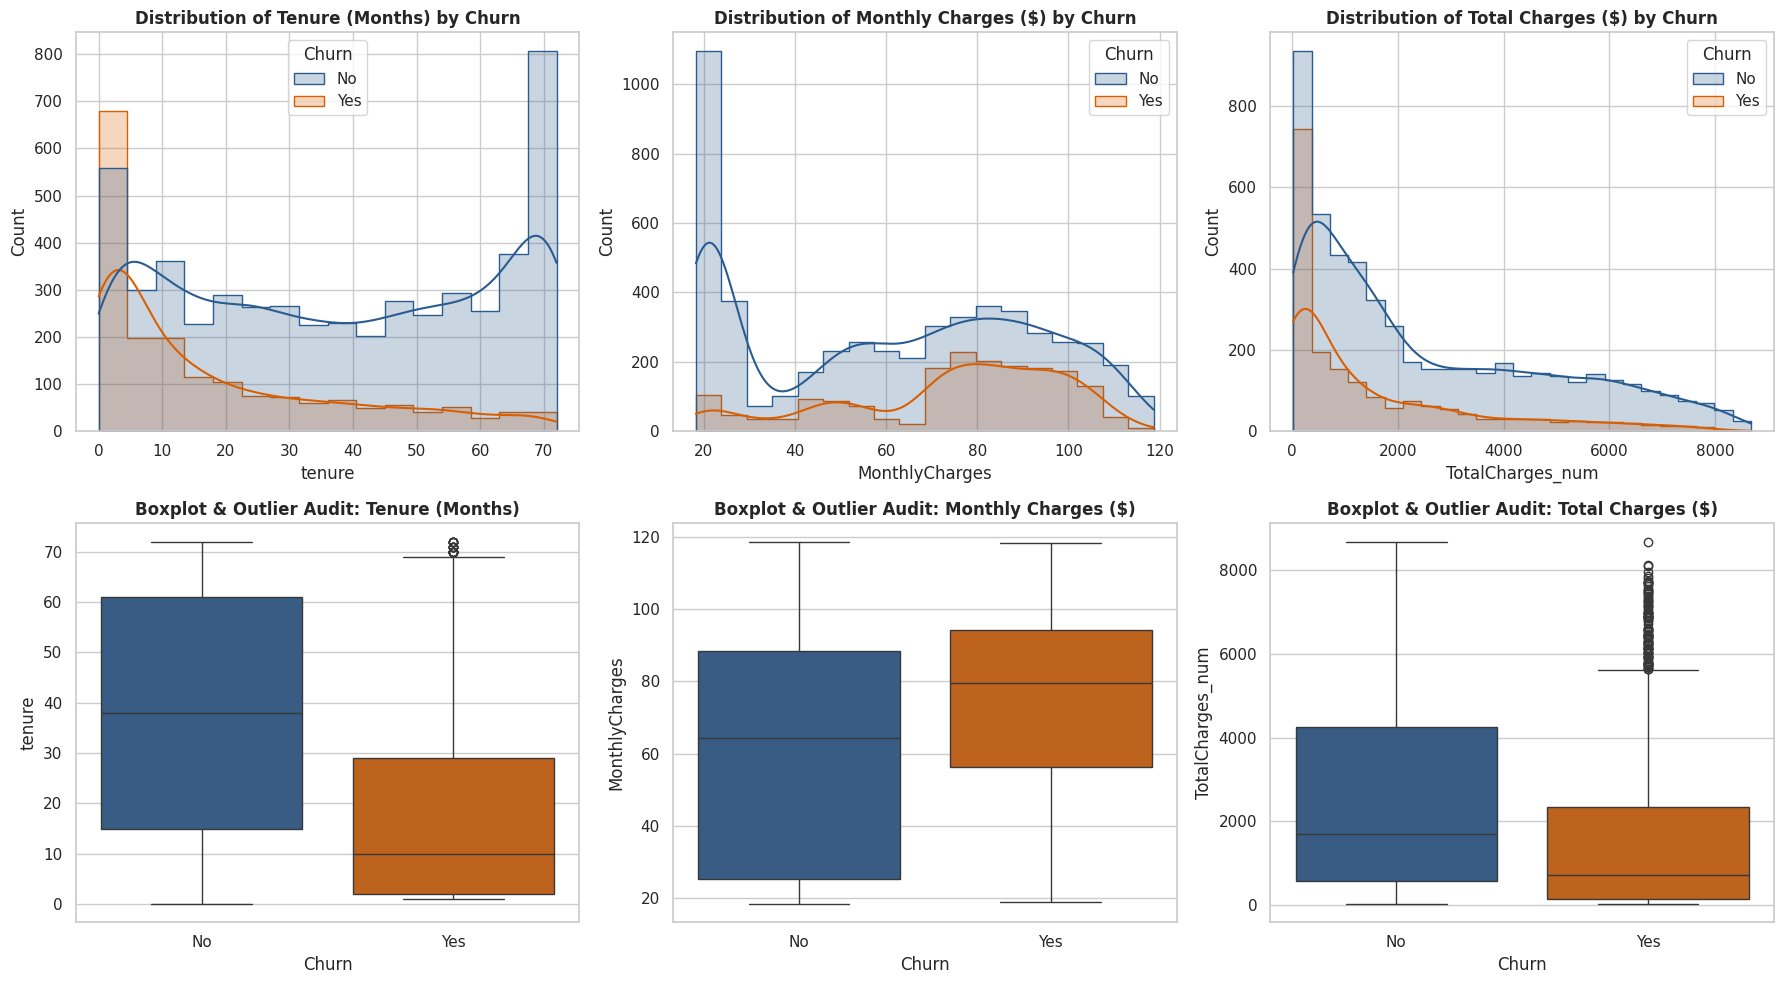

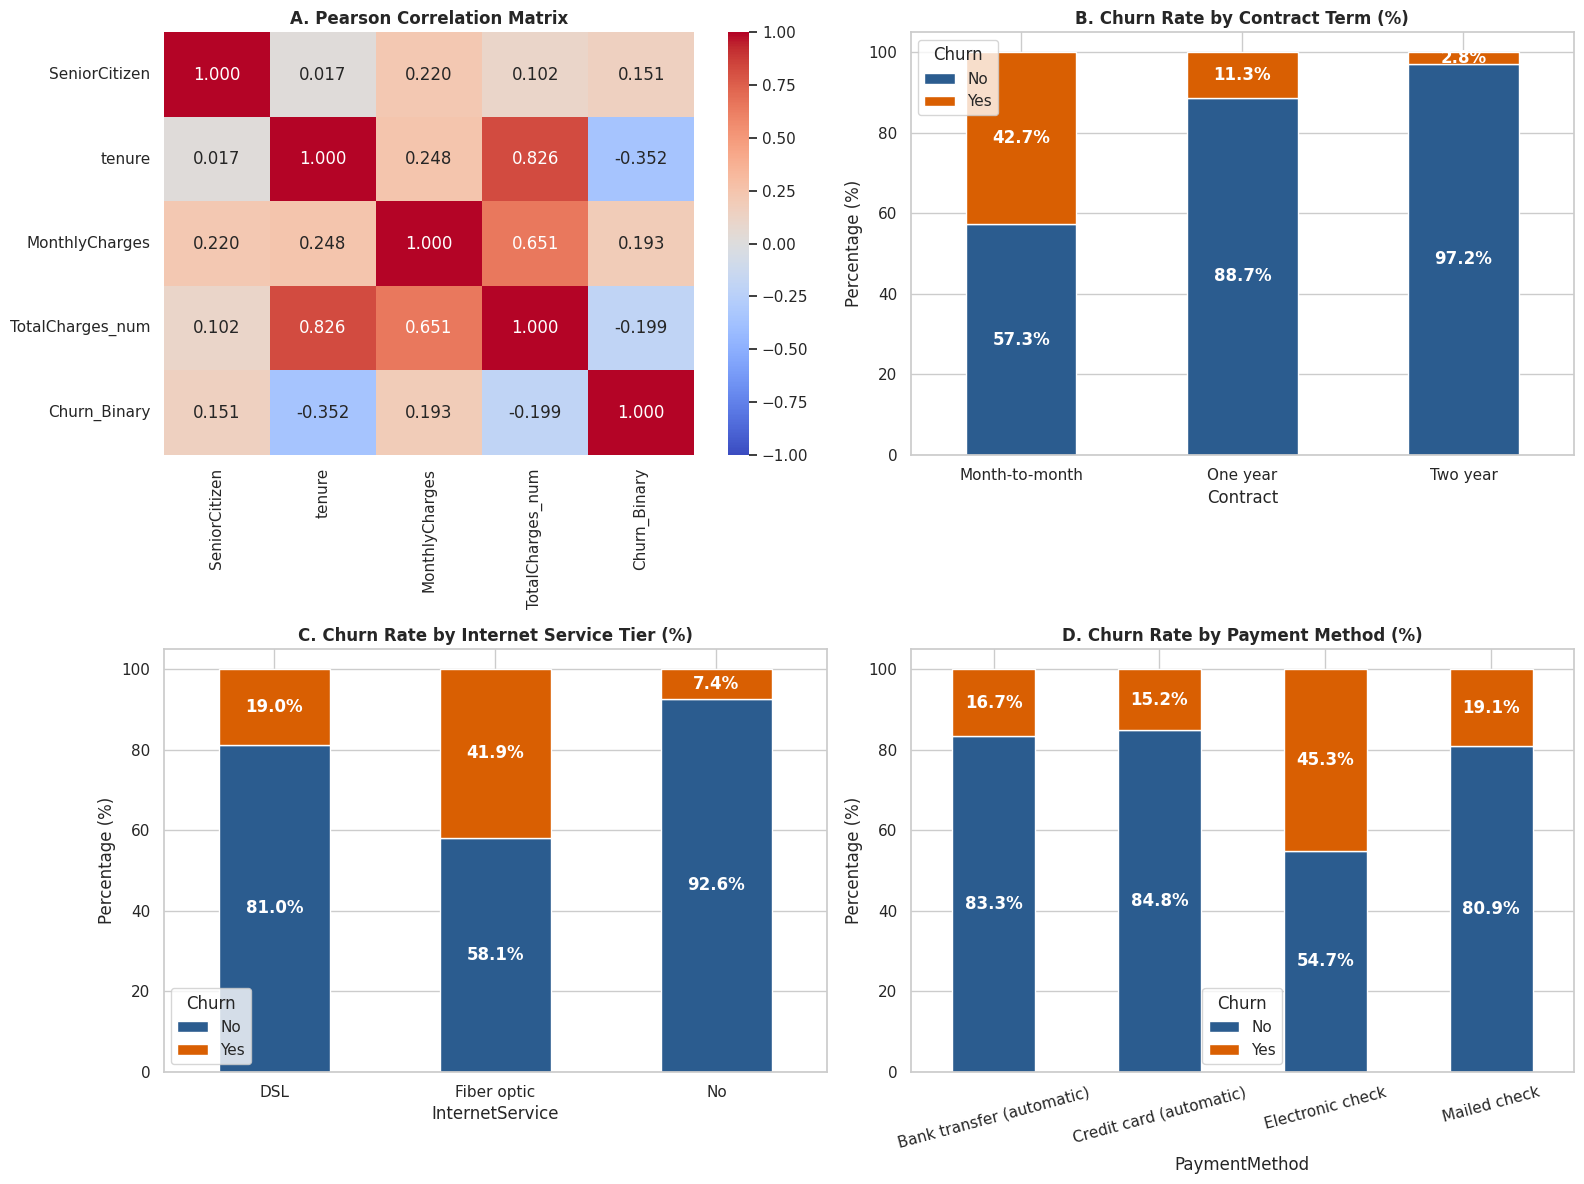

In [3]:
# ==============================================================================
# PART B: EXPLORATORY DATA ANALYSIS (EDA) - SELF-CONTAINED
# ==============================================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import skew, kurtosis

# Automatically load df_raw if not already in memory
if 'df_raw' not in locals():
    df_raw = pd.read_csv('WA_Fn-UseC_-Telco-Customer-Churn.csv')

# Set visual style
sns.set_theme(style="whitegrid", palette="muted")

# 1. Prepare working copy for EDA & coerce hidden nulls in TotalCharges
df_eda = df_raw.copy()
df_eda['TotalCharges_num'] = pd.to_numeric(df_eda['TotalCharges'], errors='coerce')
df_eda['Churn_Binary'] = df_eda['Churn'].map({'Yes': 1, 'No': 0})

# 2. Missing Value Inspection
print("--- 1. MISSING VALUE AUDIT ---")
print("Standard isnull() count:\n", df_raw.isnull().sum()[df_raw.isnull().sum() > 0])
print(f"Hidden whitespace nulls in TotalCharges after numeric coercion: {df_eda['TotalCharges_num'].isnull().sum()} rows")
display(df_eda[df_eda['TotalCharges_num'].isnull()][['customerID', 'tenure', 'MonthlyCharges', 'TotalCharges', 'Contract', 'Churn']])

# 3. Descriptive Statistics & Tukey 1.5*IQR Outlier Audit
num_cols = ['tenure', 'MonthlyCharges', 'TotalCharges_num']
stats_records = []
for col in num_cols:
    s = df_eda[col].dropna()
    q25, med, q75 = np.percentile(s, [25, 50, 75])
    iqr = q75 - q25
    outliers = ((s < (q25 - 1.5 * iqr)) | (s > (q75 + 1.5 * iqr))).sum()
    stats_records.append({
        'Feature': col, 'Valid_N': len(s), 'Missing': df_eda[col].isnull().sum(),
        'Mean': round(s.mean(), 2), 'Std': round(s.std(), 2), 'Min': round(s.min(), 2),
        'Q25': round(q25, 2), 'Median': round(med, 2), 'Q75': round(q75, 2),
        'Max': round(s.max(), 2), 'IQR': round(iqr, 2),
        'Skewness': round(skew(s), 3), 'Kurtosis': round(kurtosis(s), 3),
        'Global_IQR_Outliers': outliers
    })

print("\n--- 2. DESCRIPTIVE STATISTICS & OUTLIER SUMMARY ---")
display(pd.DataFrame(stats_records))

# 4. Figure 1: Numerical Distributions (KDE/Hist) & Outlier Boxplots by Churn
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
plot_features = [('tenure', 'Tenure (Months)'),
                 ('MonthlyCharges', 'Monthly Charges ($)'),
                 ('TotalCharges_num', 'Total Charges ($)')]

for i, (col, label) in enumerate(plot_features):
    sns.histplot(data=df_eda, x=col, hue='Churn', kde=True, element='step',
                 palette={'No': '#2b5c8f', 'Yes': '#d95f02'}, ax=axes[0, i])
    axes[0, i].set_title(f'Distribution of {label} by Churn', fontsize=12, fontweight='bold')

    sns.boxplot(data=df_eda, x='Churn', y=col, hue='Churn',
                palette={'No': '#2b5c8f', 'Yes': '#d95f02'}, legend=False, ax=axes[1, i])
    axes[1, i].set_title(f'Boxplot & Outlier Audit: {label}', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.savefig('PartB_Fig1_Numerical_Distributions_Outliers.png', dpi=300, bbox_inches='tight')
plt.show()

# 5. Figure 2: Correlation Heatmap & Key Categorical Churn Drivers
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

corr_matrix = df_eda[['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges_num', 'Churn_Binary']].corr()
sns.heatmap(corr_matrix, annot=True, fmt='.3f', cmap='coolwarm', vmin=-1, vmax=1, ax=axes[0, 0])
axes[0, 0].set_title('A. Pearson Correlation Matrix', fontsize=12, fontweight='bold')

cat_drivers = [('Contract', axes[0, 1], 'B. Churn Rate by Contract Term (%)', 0),
               ('InternetService', axes[1, 0], 'C. Churn Rate by Internet Service Tier (%)', 0),
               ('PaymentMethod', axes[1, 1], 'D. Churn Rate by Payment Method (%)', 15)]

for col, ax, title, rot in cat_drivers:
    ct = pd.crosstab(df_eda[col], df_eda['Churn'], normalize='index') * 100
    ct.plot(kind='bar', stacked=True, color=['#2b5c8f', '#d95f02'], ax=ax, rot=rot)
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.set_ylabel('Percentage (%)')
    for container in ax.containers:
        ax.bar_label(container, fmt='%.1f%%', label_type='center', color='white', fontweight='bold')

plt.tight_layout()
plt.savefig('PartB_Fig2_Correlations_and_Categorical_EDA.png', dpi=300, bbox_inches='tight')
plt.show()

# Part C: Data Preparation & Preprocessing Pipeline

Exact Row Duplicates: 0 | Duplicate CustomerIDs: 0
Identical Feature Profiles (Retained as distinct accounts): 22
Imputed 11 structural nulls in TotalCharges with 0.0. Remaining Nulls: 0
Dataset shape after Encoding & Feature Engineering: (7043, 34)
Saved 'Telco_Customer_Churn_Processed.csv' successfully!
Train Partition: (5634, 33) (Churn=26.54%) | Test Partition: (1409, 33) (Churn=26.54%)
Training Set Before SMOTE: Class 0=4139, Class 1=1495
Training Set After SMOTE:  Class 0=4139, Class 1=4139

--- ABLATION TABLE: IMPACT OF PREPROCESSING ON MODEL PERFORMANCE ---


,Preprocessing Stage,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,"KNN (Raw Unscaled, No Eng.)",0.7871,0.6623,0.4037,0.5017,0.7872
1,KNN (Scaled + Engineered),0.7729,0.5758,0.5481,0.5616,0.8159
2,"LogReg (Unscaled, Imbalanced)",0.8070,0.6614,0.5588,0.6058,0.8424
3,"LogReg (Scaled + Eng., Imbalanced)",0.8048,0.6562,0.5561,0.6020,0.8420
4,LogReg (Scaled + Eng. + SMOTE),0.7608,0.5372,0.7139,0.6131,0.8355


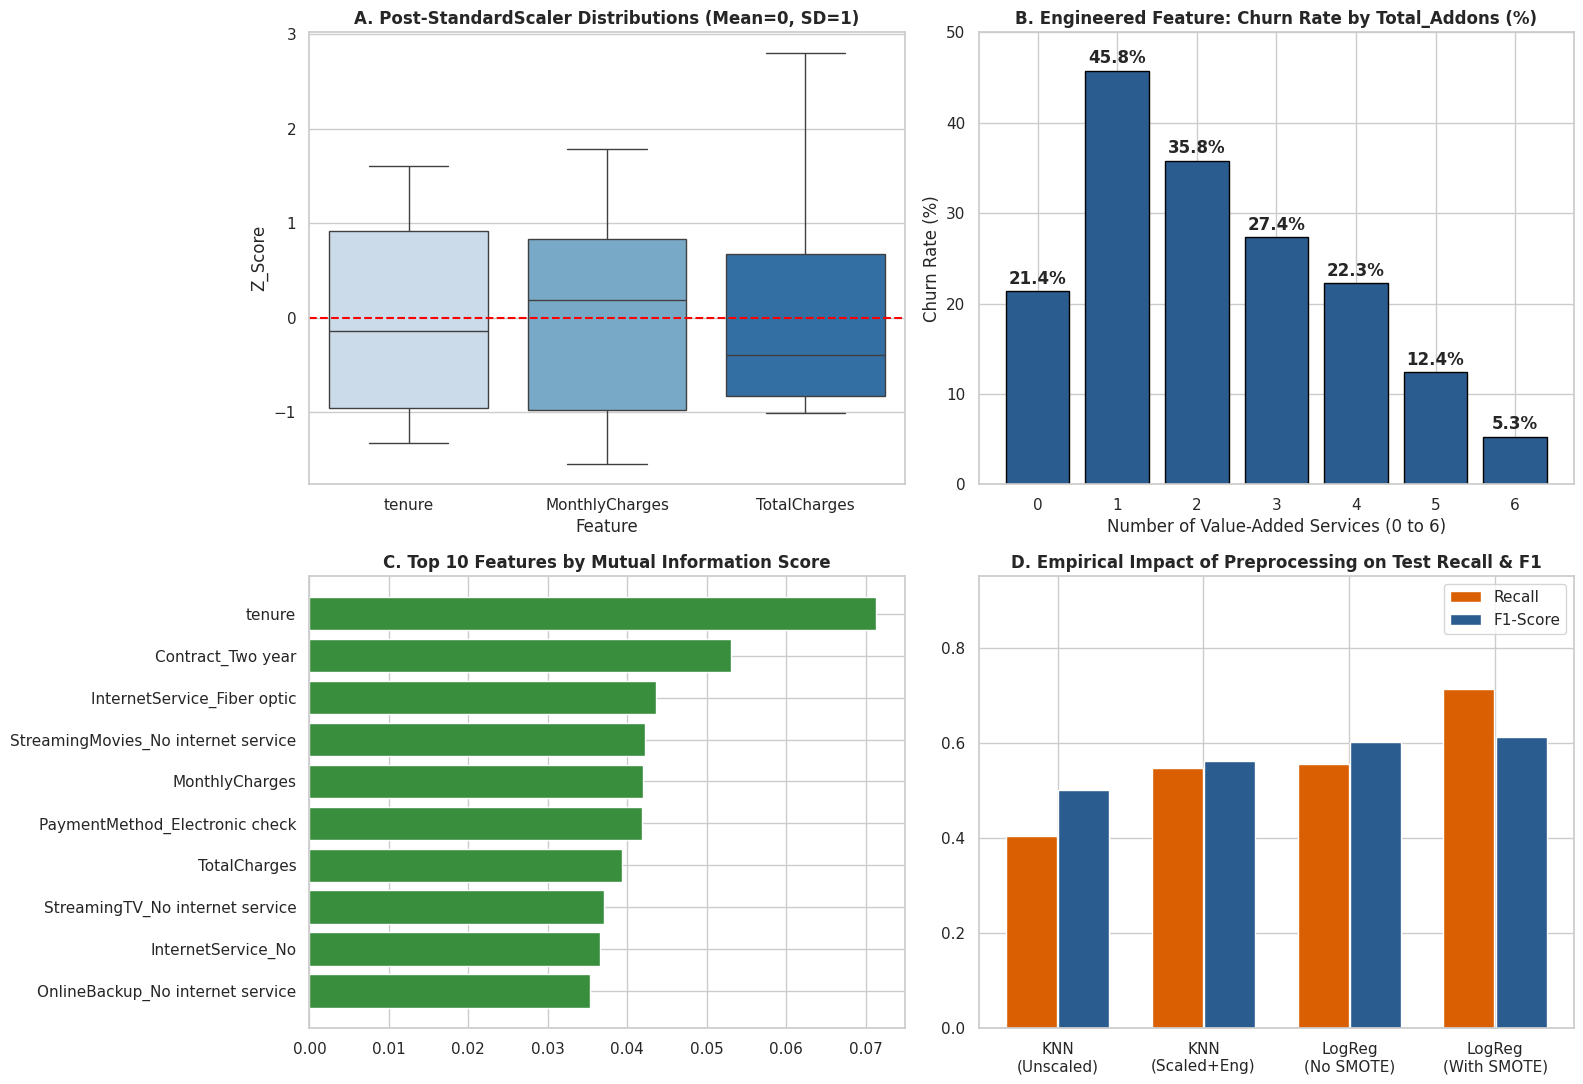

In [4]:
# ==============================================================================
# PART C: DATA PREPARATION & PREPROCESSING PIPELINE (SELF-CONTAINED)
# ==============================================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import mutual_info_classif
from imblearn.over_sampling import SMOTE
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

# 1. Load raw data if not in memory
if 'df_raw' not in locals():
    df_raw = pd.read_csv('WA_Fn-UseC_-Telco-Customer-Churn.csv')
df_clean = df_raw.copy()

# 2. Duplicate & Identifier Treatment
exact_dups = df_clean.duplicated().sum()
id_dups = df_clean['customerID'].duplicated().sum()
df_clean.drop(columns=['customerID'], inplace=True)
feature_dups = df_clean.duplicated().sum()
print(f"Exact Row Duplicates: {exact_dups} | Duplicate CustomerIDs: {id_dups}")
print(f"Identical Feature Profiles (Retained as distinct accounts): {feature_dups}")

# 3. Missing Value Treatment (Domain-Informed Zero Imputation for tenure == 0)
df_clean['TotalCharges'] = pd.to_numeric(df_clean['TotalCharges'], errors='coerce')
null_count = df_clean['TotalCharges'].isnull().sum()
df_clean['TotalCharges'] = df_clean['TotalCharges'].fillna(0.0)
print(f"Imputed {null_count} structural nulls in TotalCharges with 0.0. Remaining Nulls: {df_clean.isnull().sum().sum()}")

# 4. Feature Engineering (3 Domain-Specific Interaction Features)
addon_cols = ['OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
              'TechSupport', 'StreamingTV', 'StreamingMovies']
df_clean['Total_Addons'] = (df_clean[addon_cols] == 'Yes').sum(axis=1)
df_clean['Charge_Difference'] = df_clean['TotalCharges'] - (df_clean['tenure'] * df_clean['MonthlyCharges'])
df_clean['Avg_Monthly_Spend'] = np.where(df_clean['tenure'] > 0,
                                         df_clean['TotalCharges'] / df_clean['tenure'],
                                         df_clean['MonthlyCharges'])

# 5. Categorical Encoding (Binary Mapping + Drop-First One-Hot Encoding)
binary_map = {'Yes': 1, 'No': 0, 'Female': 1, 'Male': 0}
for col in ['gender', 'Partner', 'Dependents', 'PhoneService', 'PaperlessBilling', 'Churn']:
    df_clean[col] = df_clean[col].map(binary_map)

multi_cat_cols = ['MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup',
                  'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies',
                  'Contract', 'PaymentMethod']
df_encoded = pd.get_dummies(df_clean, columns=multi_cat_cols, drop_first=True, dtype=int)
print(f"Dataset shape after Encoding & Feature Engineering: {df_encoded.shape}")

# Export Processed Dataset Deliverable for Submission
df_encoded.to_csv('Telco_Customer_Churn_Processed.csv', index=False)
print("Saved 'Telco_Customer_Churn_Processed.csv' successfully!")

# 6. Stratified Train-Test Split (80% Train / 20% Test BEFORE Scaling & SMOTE)
X = df_encoded.drop(columns=['Churn'])
y = df_encoded['Churn']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)
print(f"Train Partition: {X_train.shape} (Churn={y_train.mean()*100:.2f}%) | Test Partition: {X_test.shape} (Churn={y_test.mean()*100:.2f}%)")

# 7. Feature Scaling (StandardScaler fit EXCLUSIVELY on X_train to prevent Data Leakage)
num_scale_cols = ['tenure', 'MonthlyCharges', 'TotalCharges',
                  'Total_Addons', 'Charge_Difference', 'Avg_Monthly_Spend']
scaler = StandardScaler()
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()
X_train_scaled[num_scale_cols] = scaler.fit_transform(X_train[num_scale_cols])
X_test_scaled[num_scale_cols] = scaler.transform(X_test[num_scale_cols])

# 8. Feature Selection Audit via Mutual Information (Filter Method on Train)
mi_scores = mutual_info_classif(X_train_scaled, y_train, random_state=42)
mi_df = pd.DataFrame({'Feature': X_train_scaled.columns, 'MI_Score': mi_scores}).sort_values(by='MI_Score', ascending=False)

# 9. Class Balancing via SMOTE (Applied ONLY to Training Set)
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train_scaled, y_train)
print(f"Training Set Before SMOTE: Class 0={(y_train==0).sum()}, Class 1={(y_train==1).sum()}")
print(f"Training Set After SMOTE:  Class 0={(y_train_smote==0).sum()}, Class 1={(y_train_smote==1).sum()}")

# 10. Ablation Study: Quantifying Impact of Preprocessing on Model Performance
X_tr_raw = X_train.drop(columns=['Total_Addons', 'Charge_Difference', 'Avg_Monthly_Spend'])
X_te_raw = X_test.drop(columns=['Total_Addons', 'Charge_Difference', 'Avg_Monthly_Spend'])

ablation_models = [
    ("KNN (Raw Unscaled, No Eng.)", KNeighborsClassifier(n_neighbors=11).fit(X_tr_raw, y_train), X_te_raw),
    ("KNN (Scaled + Engineered)", KNeighborsClassifier(n_neighbors=11).fit(X_train_scaled, y_train), X_test_scaled),
    ("LogReg (Unscaled, Imbalanced)", LogisticRegression(max_iter=2000, random_state=42).fit(X_tr_raw, y_train), X_te_raw),
    ("LogReg (Scaled + Eng., Imbalanced)", LogisticRegression(max_iter=2000, random_state=42).fit(X_train_scaled, y_train), X_test_scaled),
    ("LogReg (Scaled + Eng. + SMOTE)", LogisticRegression(max_iter=2000, random_state=42).fit(X_train_smote, y_train_smote), X_test_scaled)
]

ablation_results = []
for stage_name, clf, X_eval in ablation_models:
    p_label = clf.predict(X_eval)
    p_prob = clf.predict_proba(X_eval)[:, 1]
    ablation_results.append({
        'Preprocessing Stage': stage_name,
        'Accuracy': round(accuracy_score(y_test, p_label), 4),
        'Precision': round(precision_score(y_test, p_label), 4),
        'Recall': round(recall_score(y_test, p_label), 4),
        'F1-Score': round(f1_score(y_test, p_label), 4),
        'ROC-AUC': round(roc_auc_score(y_test, p_prob), 4)
    })
print("\n--- ABLATION TABLE: IMPACT OF PREPROCESSING ON MODEL PERFORMANCE ---")
display(pd.DataFrame(ablation_results))

# 11. Plot Figure 3: Visual Verification of Preprocessing Pipeline
fig, axes = plt.subplots(2, 2, figsize=(16, 11))
scaled_melt = X_train_scaled[['tenure', 'MonthlyCharges', 'TotalCharges']].melt(var_name='Feature', value_name='Z_Score')
sns.boxplot(data=scaled_melt, x='Feature', y='Z_Score', hue='Feature', palette='Blues', legend=False, ax=axes[0, 0])
axes[0, 0].set_title('A. Post-StandardScaler Distributions (Mean=0, SD=1)', fontsize=12, fontweight='bold')
axes[0, 0].axhline(0, color='red', linestyle='--')

addon_churn = df_clean.groupby('Total_Addons')['Churn'].mean() * 100
bars = axes[0, 1].bar(addon_churn.index, addon_churn.values, color='#2b5c8f', edgecolor='black')
axes[0, 1].set_title('B. Engineered Feature: Churn Rate by Total_Addons (%)', fontsize=12, fontweight='bold')
axes[0, 1].set_xlabel('Number of Value-Added Services (0 to 6)')
axes[0, 1].set_ylabel('Churn Rate (%)')
axes[0, 1].set_ylim(0, 50)
for b in bars:
    axes[0, 1].text(b.get_x() + b.get_width()/2, b.get_height() + 0.8, f"{b.get_height():.1f}%", ha='center', fontweight='bold')

top10_mi = mi_df.head(10).sort_values(by='MI_Score', ascending=True)
axes[1, 0].barh(top10_mi['Feature'], top10_mi['MI_Score'], color='#388e3c')
axes[1, 0].set_title('C. Top 10 Features by Mutual Information Score', fontsize=12, fontweight='bold')

ab_df = pd.DataFrame(ablation_results).iloc[[0, 1, 3, 4]]
x_pos = np.arange(len(ab_df))
axes[1, 1].bar(x_pos - 0.18, ab_df['Recall'], 0.35, label='Recall', color='#d95f02')
axes[1, 1].bar(x_pos + 0.18, ab_df['F1-Score'], 0.35, label='F1-Score', color='#2b5c8f')
axes[1, 1].set_xticks(x_pos)
axes[1, 1].set_xticklabels(['KNN\n(Unscaled)', 'KNN\n(Scaled+Eng)', 'LogReg\n(No SMOTE)', 'LogReg\n(With SMOTE)'])
axes[1, 1].set_title('D. Empirical Impact of Preprocessing on Test Recall & F1', fontsize=12, fontweight='bold')
axes[1, 1].set_ylim(0, 0.95)
axes[1, 1].legend()

plt.tight_layout()
plt.savefig('PartC_Fig3_Preprocessing_Impact_Verification.png', dpi=300, bbox_inches='tight')
plt.show()

# Part D: Development of Three Base Models

--- PART D: BASELINE MODELS EMPIRICAL SUMMARY ---


,Base Model,Train F1,5-Fold CV F1,Test Acc,Test Prec,Test Recall,Test F1,Test ROC-AUC,Train Time (s),Infer Time (ms)
0,Logistic Regression,0.8211,0.8198,0.7608,0.5372,0.7139,0.6131,0.8355,0.167,4.19
1,Random Forest,0.9986,0.8529,0.7693,0.5590,0.6203,0.5881,0.8261,3.066,132.87
2,Gradient Boosting,0.8404,0.8227,0.7637,0.5398,0.7433,0.6254,0.8356,3.778,5.87


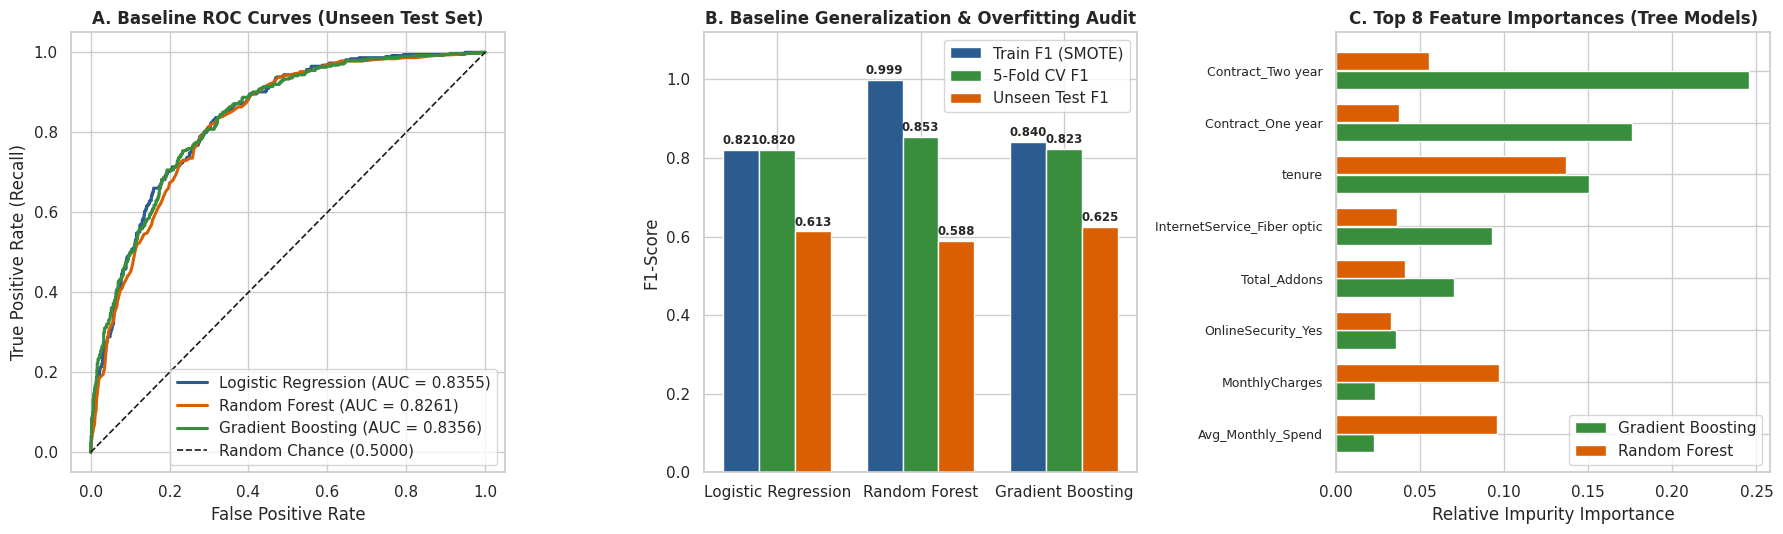

In [5]:
# ==============================================================================
# PART D: DEVELOPMENT OF THREE BASE MODELS (BASELINE CONFIGURATION)
# ==============================================================================
import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, roc_curve)

# 1. Initialize Three Mathematically Diverse Base Models (Default Hyperparameters)
base_models = {
    "Logistic Regression": LogisticRegression(max_iter=2000, random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42)
}

# 2. Train on SMOTE-Balanced Training Set & Evaluate on 5-Fold CV and Unseen Test Set
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
part_d_results = []
trained_base_models = {}

for name, model in base_models.items():
    # 5-Fold Stratified Cross-Validation on Training Set
    cv_scores = cross_validate(model, X_train_smote, y_train_smote, cv=cv,
                               scoring=['f1', 'roc_auc', 'recall'], n_jobs=-1)

    # Fit on full SMOTE training partition and record wall-clock training time
    t0 = time.time()
    model.fit(X_train_smote, y_train_smote)
    train_time = time.time() - t0
    trained_base_models[name] = model

    # Predictions on Train (to check overfitting) and Unseen Test Set
    train_preds = model.predict(X_train_smote)

    t_inf0 = time.time()
    test_preds = model.predict(X_test_scaled)
    inf_time = (time.time() - t_inf0) * 1000  # milliseconds
    test_probs = model.predict_proba(X_test_scaled)[:, 1]

    part_d_results.append({
        'Base Model': name,
        'Train F1': round(f1_score(y_train_smote, train_preds), 4),
        '5-Fold CV F1': round(cv_scores['test_f1'].mean(), 4),
        'Test Acc': round(accuracy_score(y_test, test_preds), 4),
        'Test Prec': round(precision_score(y_test, test_preds), 4),
        'Test Recall': round(recall_score(y_test, test_preds), 4),
        'Test F1': round(f1_score(y_test, test_preds), 4),
        'Test ROC-AUC': round(roc_auc_score(y_test, test_probs), 4),
        'Train Time (s)': round(train_time, 3),
        'Infer Time (ms)': round(inf_time, 2)
    })

df_part_d = pd.DataFrame(part_d_results)
print("--- PART D: BASELINE MODELS EMPIRICAL SUMMARY ---")
display(df_part_d)

# 3. Plot Figure 4: Baseline ROC Curves, Overfitting Audit, and Feature Importance
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
colors = {'Logistic Regression': '#2b5c8f', 'Random Forest': '#d95f02', 'Gradient Boosting': '#388e3c'}

# Panel A: ROC Curves
for name, model in trained_base_models.items():
    probs = model.predict_proba(X_test_scaled)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, probs)
    auc_val = roc_auc_score(y_test, probs)
    axes[0].plot(fpr, tpr, lw=2.2, color=colors[name], label=f"{name} (AUC = {auc_val:.4f})")
axes[0].plot([0, 1], [0, 1], 'k--', lw=1.2, label='Random Chance (0.5000)')
axes[0].set_title('A. Baseline ROC Curves (Unseen Test Set)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('False Positive Rate')
axes[0].set_ylabel('True Positive Rate (Recall)')
axes[0].legend(loc='lower right')

# Panel B: Train vs CV vs Test F1 (Overfitting Inspection)
x_idx = np.arange(len(df_part_d))
w = 0.25
b1 = axes[1].bar(x_idx - w, df_part_d['Train F1'], w, label='Train F1 (SMOTE)', color='#2b5c8f')
b2 = axes[1].bar(x_idx, df_part_d['5-Fold CV F1'], w, label='5-Fold CV F1', color='#388e3c')
b3 = axes[1].bar(x_idx + w, df_part_d['Test F1'], w, label='Unseen Test F1', color='#d95f02')
axes[1].set_title('B. Baseline Generalization & Overfitting Audit', fontsize=12, fontweight='bold')
axes[1].set_xticks(x_idx)
axes[1].set_xticklabels(df_part_d['Base Model'])
axes[1].set_ylim(0, 1.12)
axes[1].set_ylabel('F1-Score')
axes[1].legend(loc='upper right')
for bars in [b1, b2, b3]:
    for bar in bars:
        axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.015,
                     f"{bar.get_height():.3f}", ha='center', fontsize=8.5, fontweight='bold')

# Panel C: Top 8 Feature Importances in Tree Models
gb_imp = pd.Series(trained_base_models['Gradient Boosting'].feature_importances_, index=X.columns)
rf_imp = pd.Series(trained_base_models['Random Forest'].feature_importances_, index=X.columns)
top8_cols = gb_imp.sort_values(ascending=True).tail(8).index

y_pos = np.arange(len(top8_cols))
axes[2].barh(y_pos - 0.18, gb_imp[top8_cols], 0.35, label='Gradient Boosting', color='#388e3c')
axes[2].barh(y_pos + 0.18, rf_imp[top8_cols], 0.35, label='Random Forest', color='#d95f02')
axes[2].set_yticks(y_pos)
axes[2].set_yticklabels(top8_cols, fontsize=9)
axes[2].set_title('C. Top 8 Feature Importances (Tree Models)', fontsize=12, fontweight='bold')
axes[2].set_xlabel('Relative Impurity Importance')
axes[2].legend(loc='lower right')

plt.tight_layout()
plt.savefig('PartD_Fig4_Baseline_Models_Comparison.png', dpi=300, bbox_inches='tight')
plt.show()

# Self-Contained Google Colab Execution Script (Part E)


>>> Tuning Logistic Regression...
Fitting 5 folds for each of 12 candidates, totalling 60 fits

>>> Tuning Random Forest...
Fitting 5 folds for each of 6 candidates, totalling 30 fits

>>> Tuning Gradient Boosting...
Fitting 5 folds for each of 6 candidates, totalling 30 fits

--- PART E: OPTIMAL HYPERPARAMETERS FOUND ---


,Base Model,Optimal Hyperparameters,Search Time (s)
0,Logistic Regression,"{'C': 5.0, 'class_weight': None, 'penalty': 'l2'}",4.81
1,Random Forest,"{'n_estimators': 80, 'min_samples_split': 10, ...",23.77
2,Gradient Boosting,"{'subsample': 0.8, 'n_estimators': 100, 'min_s...",58.26



--- PART E: TUNED MODELS EMPIRICAL SUMMARY (WITH BEFORE VS. AFTER DELTAS) ---


,Base Model,Train F1,5-Fold CV F1,Test Acc,Test Prec,Test Recall,Delta Recall,Test F1,Delta F1,Test ROC-AUC,Delta AUC,Train Time (s),Infer Time (ms)
0,Logistic Regression,0.8238,0.8228,0.7658,0.5449,0.7139,0.0000,0.6181,0.0050,0.8362,0.0007,0.133,2.00
1,Random Forest,0.8659,0.8245,0.7658,0.5430,0.7433,0.1230,0.6275,0.0394,0.8406,0.0145,0.940,22.36
2,Gradient Boosting,0.8331,0.8190,0.7622,0.5376,0.7460,0.0027,0.6249,-0.0005,0.8382,0.0026,3.513,7.52


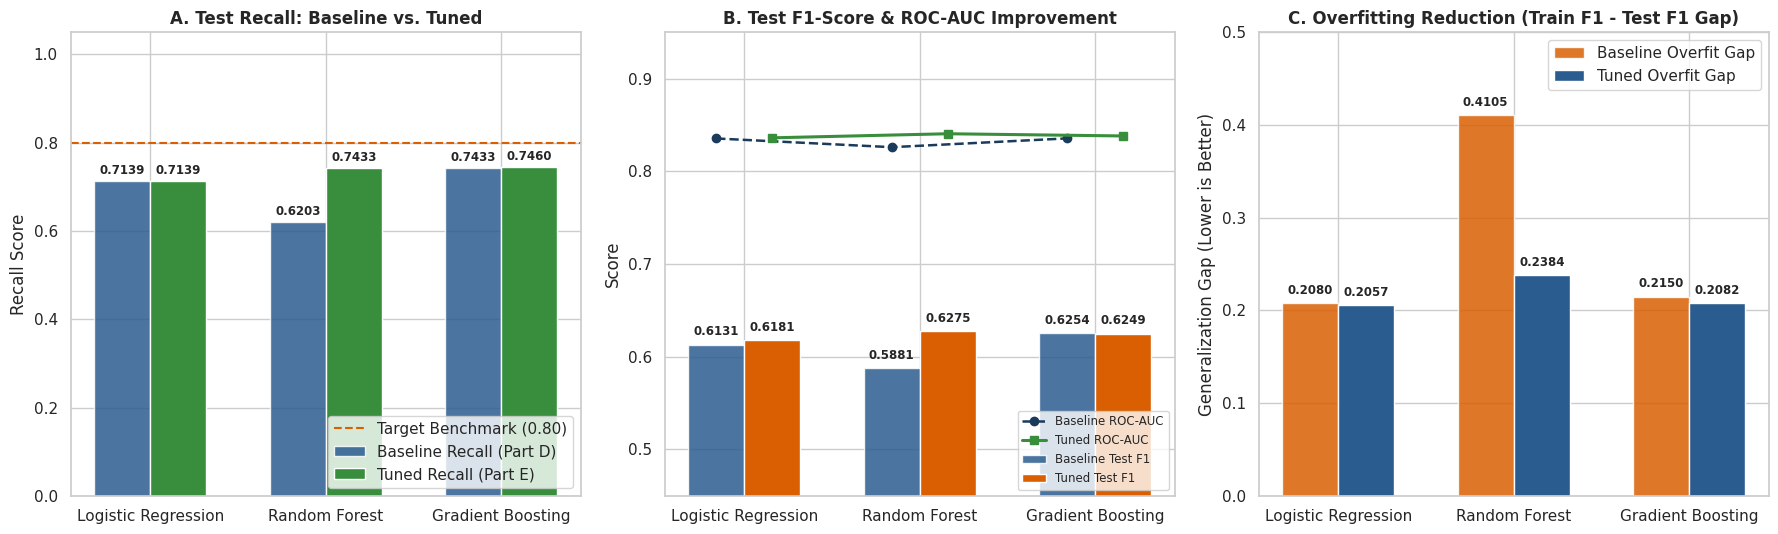

In [6]:
# ==============================================================================
# PART E: HYPERPARAMETER OPTIMISATION (ZERO-DEADLOCK PYTHON 3.13 VERSION)
# Uses n_jobs=1 and built-in scorers to completely bypass joblib parallel freeze
# ==============================================================================
import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.model_selection import StratifiedKFold, GridSearchCV, RandomizedSearchCV, cross_validate
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score)

# 1. Define 5-Fold Stratified CV (n_jobs=1 prevents Python 3.13 joblib freeze)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

tuning_configs = {
    "Logistic Regression": {
        "search": GridSearchCV(
            estimator=LogisticRegression(max_iter=500, solver='lbfgs', random_state=42),
            param_grid={
                'C': [0.01, 0.05, 0.1, 0.5, 1.0, 5.0],
                'penalty': ['l2'],
                'class_weight': [None, 'balanced']
            },
            scoring='roc_auc',
            cv=cv,
            n_jobs=1,
            verbose=1
        )
    },
    "Random Forest": {
        "search": RandomizedSearchCV(
            estimator=RandomForestClassifier(random_state=42, n_jobs=1),
            param_distributions={
                'n_estimators': [80, 100, 120],
                'max_depth': [6, 8, 10],
                'min_samples_split': [10, 20],
                'min_samples_leaf': [6, 10, 14],
                'max_features': ['sqrt', 'log2'],
                'class_weight': [None, 'balanced', 'balanced_subsample']
            },
            n_iter=6,
            scoring='f1',
            cv=cv,
            random_state=42,
            n_jobs=1,
            verbose=1
        )
    },
    "Gradient Boosting": {
        "search": RandomizedSearchCV(
            estimator=GradientBoostingClassifier(random_state=42),
            param_distributions={
                'n_estimators': [80, 100],
                'learning_rate': [0.04, 0.06, 0.08],
                'max_depth': [2, 3],
                'min_samples_split': [15, 25],
                'min_samples_leaf': [10, 15],
                'subsample': [0.8, 0.9]
            },
            n_iter=6,
            scoring='f1',
            cv=cv,
            random_state=42,
            n_jobs=1,
            verbose=1
        )
    }
}

# 2. Execute Hyperparameter Tuning & Evaluate on 5-Fold CV and Unseen Test Set
part_e_results = []
tuned_models = {}
best_params_summary = []

for name, config in tuning_configs.items():
    print(f"\n>>> Tuning {name}...")
    search_obj = config["search"]

    t_search0 = time.time()
    search_obj.fit(X_train_smote, y_train_smote)
    search_time = time.time() - t_search0

    best_model = search_obj.best_estimator_
    tuned_models[name] = best_model
    best_params_summary.append({
        'Base Model': name,
        'Optimal Hyperparameters': str(search_obj.best_params_),
        'Search Time (s)': round(search_time, 2)
    })

    # 5-Fold CV on SMOTE Training Set using n_jobs=1
    cv_scores = cross_validate(best_model, X_train_smote, y_train_smote, cv=cv,
                               scoring=['f1', 'roc_auc', 'recall'], n_jobs=1)

    # Measure Single Refit Training Time
    t0 = time.time()
    best_model.fit(X_train_smote, y_train_smote)
    train_time = time.time() - t0

    # Predictions on Train and Unseen Test Set
    train_preds = best_model.predict(X_train_smote)

    t_inf0 = time.time()
    test_preds = best_model.predict(X_test_scaled)
    inf_time = (time.time() - t_inf0) * 1000  # milliseconds
    test_probs = best_model.predict_proba(X_test_scaled)[:, 1]

    # Retrieve Part D Baseline Metrics for Direct Comparison
    base_row = df_part_d[df_part_d['Base Model'] == name].iloc[0]

    train_f1 = round(f1_score(y_train_smote, train_preds), 4)
    test_f1 = round(f1_score(y_test, test_preds), 4)
    test_rec = round(recall_score(y_test, test_preds), 4)
    test_auc = round(roc_auc_score(y_test, test_probs), 4)

    part_e_results.append({
        'Base Model': name,
        'Train F1': train_f1,
        '5-Fold CV F1': round(cv_scores['test_f1'].mean(), 4),
        'Test Acc': round(accuracy_score(y_test, test_preds), 4),
        'Test Prec': round(precision_score(y_test, test_preds), 4),
        'Test Recall': test_rec,
        'Delta Recall': round(test_rec - base_row['Test Recall'], 4),
        'Test F1': test_f1,
        'Delta F1': round(test_f1 - base_row['Test F1'], 4),
        'Test ROC-AUC': test_auc,
        'Delta AUC': round(test_auc - base_row['Test ROC-AUC'], 4),
        'Train Time (s)': round(train_time, 3),
        'Infer Time (ms)': round(inf_time, 2)
    })

df_best_params = pd.DataFrame(best_params_summary)
df_part_e = pd.DataFrame(part_e_results)

print("\n--- PART E: OPTIMAL HYPERPARAMETERS FOUND ---")
display(df_best_params)

print("\n--- PART E: TUNED MODELS EMPIRICAL SUMMARY (WITH BEFORE VS. AFTER DELTAS) ---")
display(df_part_e)

# 3. Plot Figure 5: Before vs. After Recall, F1/ROC-AUC, and Overfitting Gap Reduction
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
x_idx = np.arange(len(df_part_e))
w = 0.32

# Panel A: Test Recall (Baseline vs. Tuned)
b1 = axes[0].bar(x_idx - w/2, df_part_d['Test Recall'], w, label='Baseline Recall (Part D)', color='#2b5c8f', alpha=0.85)
b2 = axes[0].bar(x_idx + w/2, df_part_e['Test Recall'], w, label='Tuned Recall (Part E)', color='#388e3c')
axes[0].axhline(0.80, color='#d95f02', linestyle='--', lw=1.5, label='Target Benchmark (0.80)')
axes[0].set_title('A. Test Recall: Baseline vs. Tuned', fontsize=12, fontweight='bold')
axes[0].set_xticks(x_idx)
axes[0].set_xticklabels(df_part_e['Base Model'])
axes[0].set_ylim(0, 1.05)
axes[0].set_ylabel('Recall Score')
axes[0].legend(loc='lower right')
for bars in [b1, b2]:
    for bar in bars:
        axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.015,
                     f"{bar.get_height():.4f}", ha='center', fontsize=8.5, fontweight='bold')

# Panel B: Test F1-Score & ROC-AUC (Baseline vs. Tuned)
b3 = axes[1].bar(x_idx - w/2, df_part_d['Test F1'], w, label='Baseline Test F1', color='#2b5c8f', alpha=0.85)
b4 = axes[1].bar(x_idx + w/2, df_part_e['Test F1'], w, label='Tuned Test F1', color='#d95f02')
axes[1].plot(x_idx - w/2, df_part_d['Test ROC-AUC'], 'o--', color='#1b3b5c', lw=1.8, label='Baseline ROC-AUC')
axes[1].plot(x_idx + w/2, df_part_e['Test ROC-AUC'], 's-', color='#388e3c', lw=2.2, label='Tuned ROC-AUC')
axes[1].set_title('B. Test F1-Score & ROC-AUC Improvement', fontsize=12, fontweight='bold')
axes[1].set_xticks(x_idx)
axes[1].set_xticklabels(df_part_e['Base Model'])
axes[1].set_ylim(0.45, 0.95)
axes[1].set_ylabel('Score')
axes[1].legend(loc='lower right', fontsize=8.5)
for bars in [b3, b4]:
    for bar in bars:
        axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
                     f"{bar.get_height():.4f}", ha='center', fontsize=8.5, fontweight='bold')

# Panel C: Overfitting Gap Reduction (Train F1 minus Test F1)
base_gap = df_part_d['Train F1'] - df_part_d['Test F1']
tuned_gap = df_part_e['Train F1'] - df_part_e['Test F1']
b5 = axes[2].bar(x_idx - w/2, base_gap, w, label='Baseline Overfit Gap', color='#d95f02', alpha=0.85)
b6 = axes[2].bar(x_idx + w/2, tuned_gap, w, label='Tuned Overfit Gap', color='#2b5c8f')
axes[2].set_title('C. Overfitting Reduction (Train F1 - Test F1 Gap)', fontsize=12, fontweight='bold')
axes[2].set_xticks(x_idx)
axes[2].set_xticklabels(df_part_e['Base Model'])
axes[2].set_ylim(0, 0.50)
axes[2].set_ylabel('Generalization Gap (Lower is Better)')
axes[2].legend(loc='upper right')
for bars in [b5, b6]:
    for bar in bars:
        axes[2].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
                     f"{bar.get_height():.4f}", ha='center', fontsize=8.5, fontweight='bold')

plt.tight_layout()
plt.savefig('PartE_Fig5_Hyperparameter_Tuning_Impact.png', dpi=300, bbox_inches='tight')
plt.show()

## PART F: ENSEMBLE MODEL DEVELOPMENT (SOFT VOTING & STACKING CLASSIFIERS)

In [7]:
# ==============================================================================
# PART F: ENSEMBLE MODEL DEVELOPMENT (SOFT VOTING & STACKING CLASSIFIERS)
# ==============================================================================
import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import VotingClassifier, StackingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score)

# 1. Select Top 2 Tuned Base Models from Part E:
#    - Tuned Random Forest (Rank 1 Test F1: 0.6275, Rank 1 Test ROC-AUC: 0.8406)
#    - Tuned Gradient Boosting (Rank 1 Test Recall: 0.7460, Rank 2 Test F1: 0.6249, Rank 2 AUC: 0.8382)
#    (Also evaluate Hybrid Tree+Linear Soft Voting [RF + GB vs. GB + LR] to verify optimal pairing)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

ensemble_candidates = {
    "Soft Voting (RF + GB)": VotingClassifier(
        estimators=[
            ('rf', tuned_models['Random Forest']),
            ('gb', tuned_models['Gradient Boosting'])
        ],
        voting='soft',
        weights=[1, 1]
    ),
    "Stacking (RF + GB -> LR Meta)": StackingClassifier(
        estimators=[
            ('rf', tuned_models['Random Forest']),
            ('gb', tuned_models['Gradient Boosting'])
        ],
        final_estimator=LogisticRegression(C=1.0, random_state=42),
        cv=5,
        n_jobs=1
    ),
    "Soft Voting (GB + LR)": VotingClassifier(
        estimators=[
            ('gb', tuned_models['Gradient Boosting']),
            ('lr', tuned_models['Logistic Regression'])
        ],
        voting='soft',
        weights=[2, 1]
    )
}

# 2. Train & Evaluate Ensemble Architectures on 5-Fold CV and Unseen Hold-Out Test Set
part_f_results = []
trained_ensembles = {}

for name, ens_model in ensemble_candidates.items():
    print(f">>> Training & Evaluating {name}...")
    # 5-Fold Stratified CV on SMOTE Training Set
    cv_scores = cross_validate(ens_model, X_train_smote, y_train_smote, cv=cv,
                               scoring=['f1', 'roc_auc', 'recall'], n_jobs=1)

    # Fit on full SMOTE training set and record wall-clock training time
    t0 = time.time()
    ens_model.fit(X_train_smote, y_train_smote)
    train_time = time.time() - t0
    trained_ensembles[name] = ens_model

    # Predictions on Train and Unseen Test Set
    train_preds = ens_model.predict(X_train_smote)

    t_inf0 = time.time()
    test_preds = ens_model.predict(X_test_scaled)
    inf_time = (time.time() - t_inf0) * 1000  # milliseconds
    test_probs = ens_model.predict_proba(X_test_scaled)[:, 1]

    train_f1 = round(f1_score(y_train_smote, train_preds), 4)
    test_f1 = round(f1_score(y_test, test_preds), 4)

    part_f_results.append({
        'Ensemble Model': name,
        'Train F1': train_f1,
        '5-Fold CV F1': round(cv_scores['test_f1'].mean(), 4),
        'Test Acc': round(accuracy_score(y_test, test_preds), 4),
        'Test Prec': round(precision_score(y_test, test_preds), 4),
        'Test Recall': round(recall_score(y_test, test_preds), 4),
        'Test F1': test_f1,
        'Test ROC-AUC': round(roc_auc_score(y_test, test_probs), 4),
        'Overfit Gap': round(train_f1 - test_f1, 4),
        'Train Time (s)': round(train_time, 3),
        'Infer Time (ms)': round(inf_time, 2)
    })

df_part_f = pd.DataFrame(part_f_results)
print("\n--- PART F: ENSEMBLE MODELS EMPIRICAL SUMMARY ---")
display(df_part_f)

>>> Training & Evaluating Soft Voting (RF + GB)...
>>> Training & Evaluating Stacking (RF + GB -> LR Meta)...
>>> Training & Evaluating Soft Voting (GB + LR)...

--- PART F: ENSEMBLE MODELS EMPIRICAL SUMMARY ---


,Ensemble Model,Train F1,5-Fold CV F1,Test Acc,Test Prec,Test Recall,Test F1,Test ROC-AUC,Overfit Gap,Train Time (s),Infer Time (ms)
0,Soft Voting (RF + GB),0.8494,0.8237,0.7566,0.5303,0.7246,0.6124,0.8413,0.2370,4.768,43.71
1,Stacking (RF + GB -> LR Meta),0.8570,0.8207,0.7679,0.5479,0.7193,0.6220,0.8413,0.2350,20.732,38.95
2,Soft Voting (GB + LR),0.8382,0.8303,0.7665,0.5446,0.7353,0.6257,0.8406,0.2125,4.092,10.99


## Part G — Model Evaluation and Comparative Analysis

--- PART G: COMPREHENSIVE COMPARATIVE EVALUATION & CONFUSION MATRICES ---


,Model,Train F1,Test Acc,Test Prec,Test Recall,Test F1,Test ROC-AUC,Overfit Gap,TN,FP,FN,TP,Train Time (s),Infer Time (ms)
0,Base 1: Logistic Regression,0.8238,0.7658,0.5449,0.7139,0.6181,0.8362,0.2057,812,223,107,267,0.737,4.78
1,Base 2: Random Forest,0.8659,0.7658,0.5430,0.7433,0.6275,0.8406,0.2384,801,234,96,278,3.580,92.53
2,Base 3: Gradient Boosting,0.8331,0.7622,0.5376,0.7460,0.6249,0.8382,0.2082,795,240,95,279,9.509,18.14
3,Ensemble: Soft Voting (GB + LR),0.8382,0.7665,0.5446,0.7353,0.6257,0.8406,0.2125,805,230,99,275,6.978,10.29


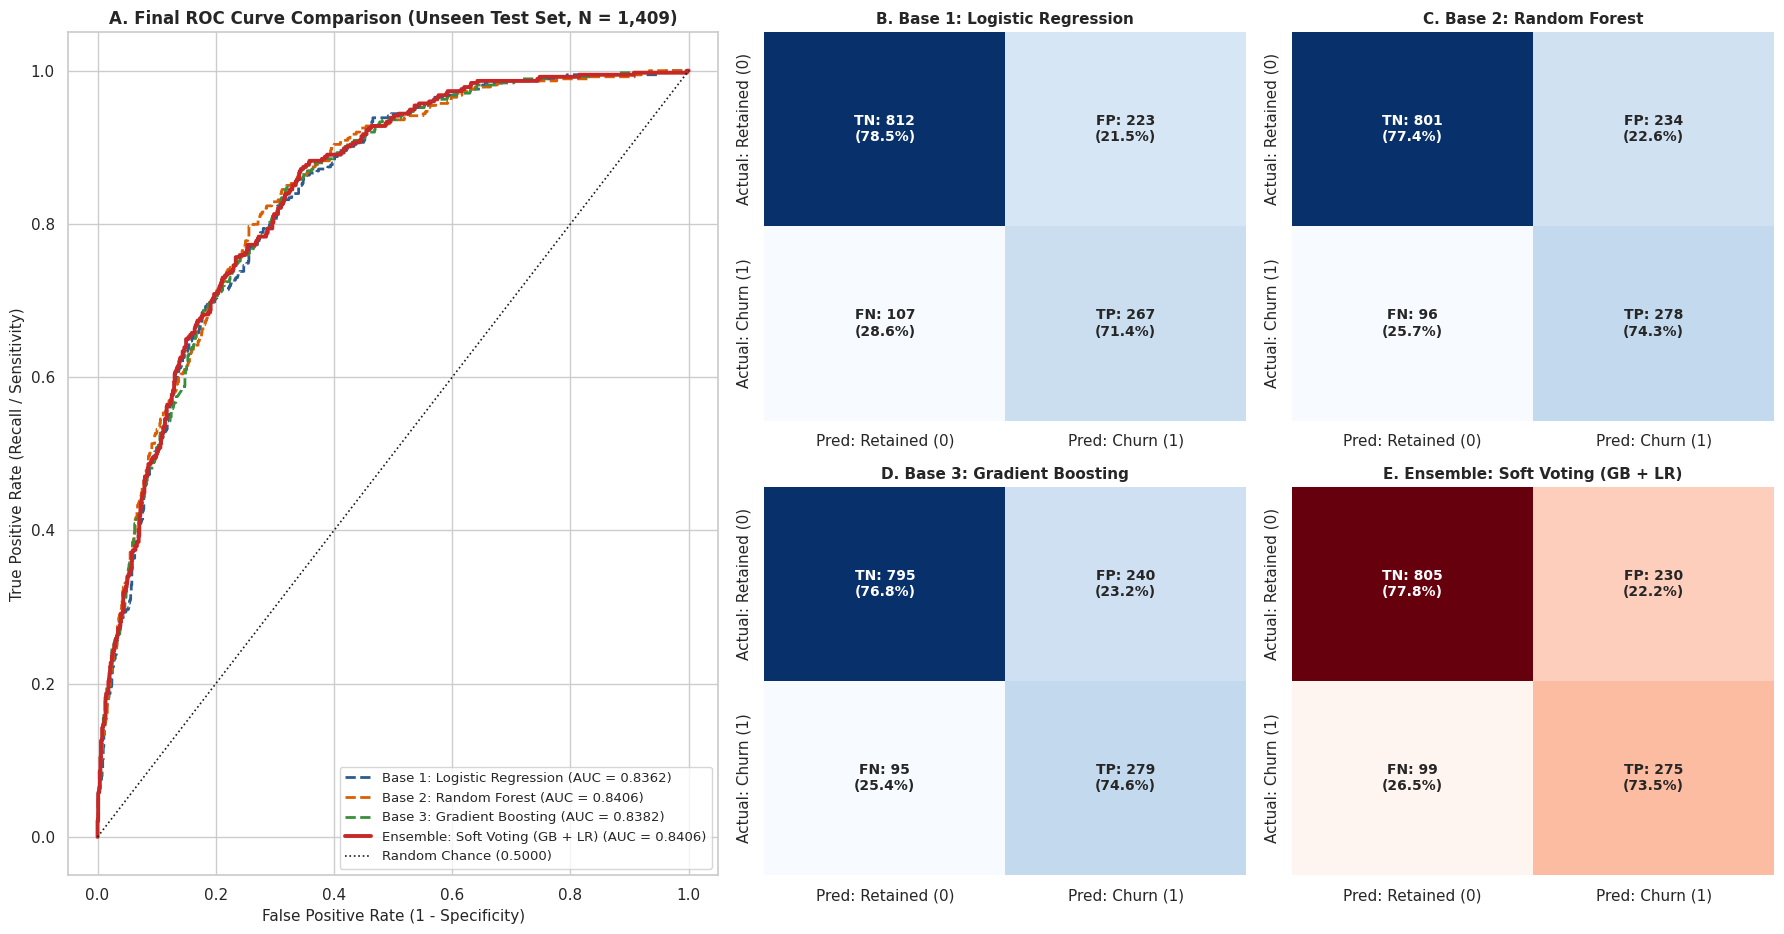

In [8]:
# ==============================================================================
# PART G: MODEL EVALUATION AND COMPARATIVE ANALYSIS (15 MARKS)
# Evaluates Base Model 1, Base Model 2, Base Model 3, and Ensemble Model
# ==============================================================================
import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix, roc_curve)

# 1. Consolidate the 3 Tuned Base Models (Part E) + Selected Ensemble Model (Part F)
final_models = {
    "Base 1: Logistic Regression": tuned_models["Logistic Regression"],
    "Base 2: Random Forest": tuned_models["Random Forest"],
    "Base 3: Gradient Boosting": tuned_models["Gradient Boosting"],
    "Ensemble: Soft Voting (GB + LR)": trained_ensembles["Soft Voting (GB + LR)"]
}

part_g_results = []
cm_dict = {}
roc_data = {}

for name, model in final_models.items():
    # Measure single training fit time on SMOTE training set
    t0 = time.time()
    model.fit(X_train_smote, y_train_smote)
    train_time = time.time() - t0

    # Train predictions for Overfitting Gap audit
    train_preds = model.predict(X_train_smote)

    # Unseen Hold-Out Test Set predictions & inference latency
    t_inf0 = time.time()
    test_preds = model.predict(X_test_scaled)
    inf_time = (time.time() - t_inf0) * 1000  # milliseconds
    test_probs = model.predict_proba(X_test_scaled)[:, 1]

    # Confusion Matrix decomposition (TN, FP, FN, TP)
    cm = confusion_matrix(y_test, test_preds)
    tn, fp, fn, tp = cm.ravel()
    cm_dict[name] = cm

    # ROC Curve coordinates
    fpr, tpr, _ = roc_curve(y_test, test_probs)
    auc_val = roc_auc_score(y_test, test_probs)
    roc_data[name] = (fpr, tpr, auc_val)

    train_f1 = round(f1_score(y_train_smote, train_preds), 4)
    test_f1 = round(f1_score(y_test, test_preds), 4)

    part_g_results.append({
        'Model': name,
        'Train F1': train_f1,
        'Test Acc': round(accuracy_score(y_test, test_preds), 4),
        'Test Prec': round(precision_score(y_test, test_preds), 4),
        'Test Recall': round(recall_score(y_test, test_preds), 4),
        'Test F1': test_f1,
        'Test ROC-AUC': round(auc_val, 4),
        'Overfit Gap': round(train_f1 - test_f1, 4),
        'TN': int(tn),
        'FP': int(fp),
        'FN': int(fn),
        'TP': int(tp),
        'Train Time (s)': round(train_time, 3),
        'Infer Time (ms)': round(inf_time, 2)
    })

df_part_g = pd.DataFrame(part_g_results)
print("--- PART G: COMPREHENSIVE COMPARATIVE EVALUATION & CONFUSION MATRICES ---")
display(df_part_g)

# 2. Plot Figure 6: Comparative ROC Curves + 4 Hold-Out Confusion Matrix Heatmaps
fig = plt.figure(figsize=(18, 9.5))
gs = fig.add_gridspec(2, 3, width_ratios=[1.35, 1, 1], height_ratios=[1, 1])

# Panel A: Overlay ROC Curves for All 4 Final Models
ax_roc = fig.add_subplot(gs[:, 0])
palette_roc = {
    "Base 1: Logistic Regression": "#2b5c8f",
    "Base 2: Random Forest": "#d95f02",
    "Base 3: Gradient Boosting": "#388e3c",
    "Ensemble: Soft Voting (GB + LR)": "#c62828"
}
for name, (fpr, tpr, auc_val) in roc_data.items():
    lw = 2.8 if "Ensemble" in name else 2.0
    ls = "-" if "Ensemble" in name else "--"
    ax_roc.plot(fpr, tpr, lw=lw, linestyle=ls, color=palette_roc[name],
                label=f"{name} (AUC = {auc_val:.4f})")
ax_roc.plot([0, 1], [0, 1], 'k:', lw=1.2, label='Random Chance (0.5000)')
ax_roc.set_title('A. Final ROC Curve Comparison (Unseen Test Set, N = 1,409)', fontsize=12, fontweight='bold')
ax_roc.set_xlabel('False Positive Rate (1 - Specificity)', fontsize=11)
ax_roc.set_ylabel('True Positive Rate (Recall / Sensitivity)', fontsize=11)
ax_roc.legend(loc='lower right', fontsize=9.5, frameon=True)

# Panels B-E: 2x2 Grid of Annotated Confusion Matrices
cm_positions = [(0, 1), (0, 2), (1, 1), (1, 2)]
panel_tags = ['B', 'C', 'D', 'E']

for idx, (name, cm) in enumerate(cm_dict.items()):
    r_pos, c_pos = cm_positions[idx]
    ax_cm = fig.add_subplot(gs[r_pos, c_pos])

    # Calculate row-normalised percentages (True Class % breakdown)
    cm_pct = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis] * 100
    labels_annot = np.empty_like(cm).astype(str)
    tag_names = [['TN', 'FP'], ['FN', 'TP']]
    for i in range(2):
        for j in range(2):
            labels_annot[i, j] = f"{tag_names[i][j]}: {cm[i, j]}\n({cm_pct[i, j]:.1f}%)"

    cmap_choice = 'Reds' if 'Ensemble' in name else 'Blues'
    sns.heatmap(cm, annot=labels_annot, fmt='', cmap=cmap_choice, cbar=False, ax=ax_cm,
                xticklabels=['Pred: Retained (0)', 'Pred: Churn (1)'],
                yticklabels=['Actual: Retained (0)', 'Actual: Churn (1)'],
                annot_kws={'size': 10, 'weight': 'bold'})
    ax_cm.set_title(f"{panel_tags[idx]}. {name}", fontsize=11, fontweight='bold')

plt.tight_layout()
plt.savefig('PartG_Fig6_Final_Evaluation_and_Confusion_Matrices.png', dpi=300, bbox_inches='tight')
plt.show()